# Bitcoin Price Forecast

The series is the daily Bitcoin close from 2013 to 2021. The level trends hard, and the next day still depends on the recent path. I will plot the close, the 30-day mean, the daily returns and a seasonal decomposition, then train two models on a chronological 80/20 split. The first is linear regression on the last 30 closes. The second is a 1D CNN. The deep model is the one I want here. I will compare RMSE in dollars and save the CNN.


In [1]:
import kagglehub

path = kagglehub.dataset_download("sudalairajkumar/cryptocurrencypricehistory")
print("Path to dataset files:", path)


Path to dataset files: C:\Users\Administrator\.cache\kagglehub\datasets\sudalairajkumar\cryptocurrencypricehistory\versions\3


In [2]:
import os
import glob
import pandas as pd

csv_path = glob.glob(os.path.join(path, "**", "coin_Bitcoin.csv"), recursive=True)[0]
df = pd.read_csv(csv_path)
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").set_index("Date")
df.head()


,SNo,Name,Symbol,High,Low,Open,Close,Volume,Marketcap
Date,,,,,,,,,
2013-04-29 23:59:59,1,Bitcoin,BTC,147.488007,134.000000,134.444000,144.539993,0.0,1.603769e+09
2013-04-30 23:59:59,2,Bitcoin,BTC,146.929993,134.050003,144.000000,139.000000,0.0,1.542813e+09
2013-05-01 23:59:59,3,Bitcoin,BTC,139.889999,107.720001,139.000000,116.989998,0.0,1.298955e+09
2013-05-02 23:59:59,4,Bitcoin,BTC,125.599998,92.281898,116.379997,105.209999,0.0,1.168517e+09
2013-05-03 23:59:59,5,Bitcoin,BTC,108.127998,79.099998,106.250000,97.750000,0.0,1.085995e+09


In [3]:
print(df.shape)
print(df.index.min(), df.index.max())
df["Close"].describe()


(2991, 9)
2013-04-29 23:59:59 2021-07-06 23:59:59


count     2991.000000
mean      6711.290443
std      11298.141921
min         68.431000
25%        430.569489
50%       2286.409912
75%       8576.238715
max      63503.457930
Name: Close, dtype: float64

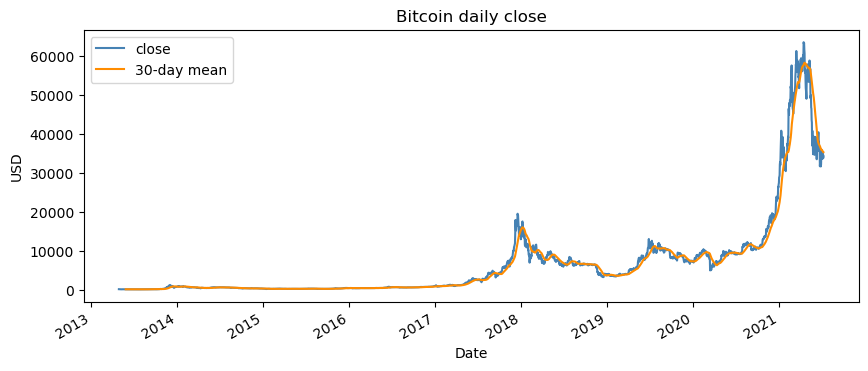

In [4]:
import matplotlib.pyplot as plt

df["Close"].plot(figsize=(10, 4), color="steelblue", label="close")
df["Close"].rolling(30).mean().plot(color="darkorange", label="30-day mean")
plt.title("Bitcoin daily close")
plt.ylabel("USD")
plt.legend()
plt.show()


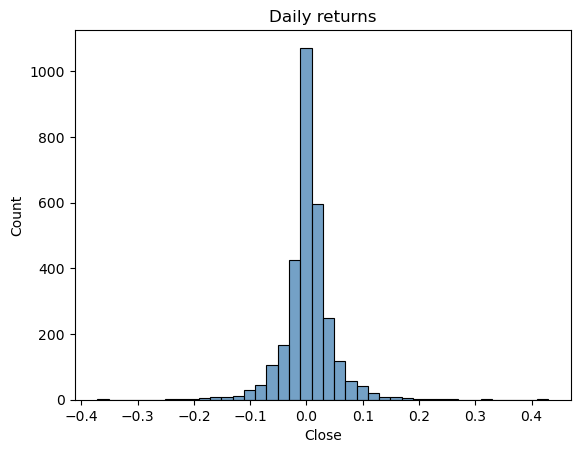

In [5]:
import seaborn as sns

sns.histplot(df["Close"].pct_change().dropna(), bins=40, color="steelblue")
plt.title("Daily returns")
plt.show()


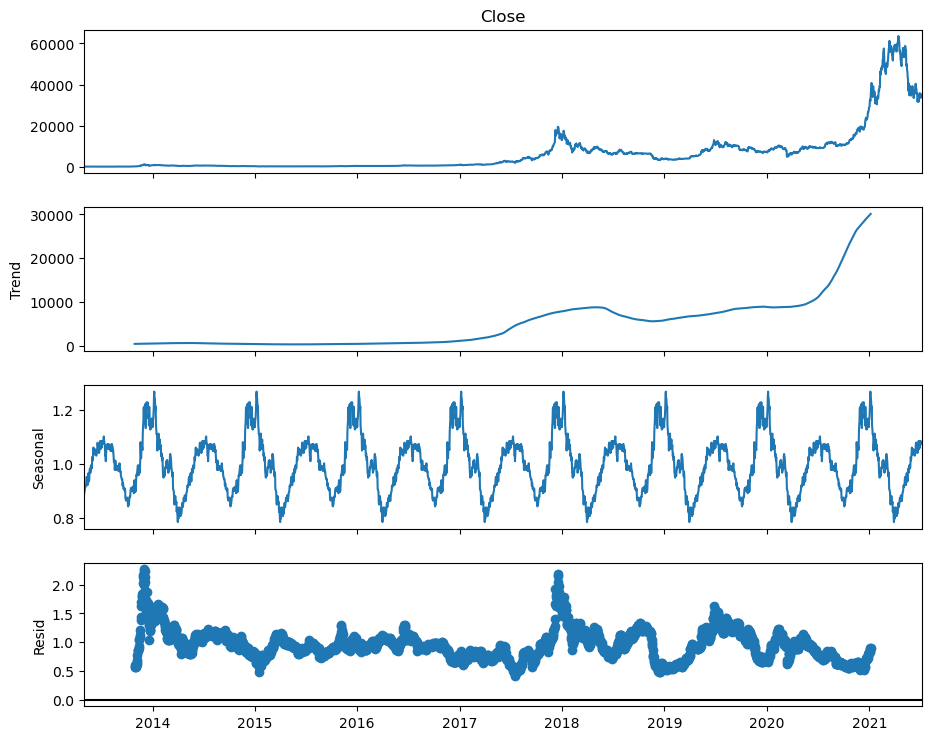

In [6]:
from statsmodels.tsa.seasonal import seasonal_decompose

result = seasonal_decompose(df["Close"], model="multiplicative", period=365)
fig = result.plot()
fig.set_size_inches(10, 8)
plt.show()


In [7]:
import numpy as np
from numpy.lib.stride_tricks import sliding_window_view
from sklearn.preprocessing import MinMaxScaler

window = 30
raw = df[["Close"]].to_numpy()
split_raw = int(len(raw) * 0.8)
scaler = MinMaxScaler()
scaled = scaler.fit_transform(raw).ravel()
x = sliding_window_view(scaled, window)[:-1][..., None]
y = scaled[window:]
n_train = split_raw - window
x_train, x_test = x[:n_train], x[n_train:]
y_train, y_test = y[:n_train], y[n_train:]
print(x_train.shape, x_test.shape)


(2362, 30, 1) (599, 30, 1)


In [8]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

lin = LinearRegression()
lin.fit(x_train.reshape(len(x_train), -1), y_train)
lin_pred = lin.predict(x_test.reshape(len(x_test), -1))
print("Linear RMSE", np.sqrt(mean_squared_error(
    scaler.inverse_transform(y_test.reshape(-1, 1)),
    scaler.inverse_transform(lin_pred.reshape(-1, 1)),
)))


Linear RMSE 1260.3144438209724


In [9]:
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(42)

dl = tf.keras.Sequential([
    layers.Input(shape=(window, 1)),
    layers.Conv1D(32, 3, activation="relu"),
    layers.MaxPooling1D(2),
    layers.Conv1D(32, 3, activation="relu"),
    layers.GlobalAveragePooling1D(),
    layers.Dropout(0.2),
    layers.Dense(1),
])
dl.compile(optimizer="adam", loss="mse")
hist = dl.fit(
    x_train, y_train,
    validation_split=0.1,
    epochs=12,
    batch_size=32,
    callbacks=[EarlyStopping(patience=2, restore_best_weights=True)],
    verbose=1,
)
dl_pred = dl.predict(x_test, verbose=0).ravel()
print("CNN RMSE", np.sqrt(mean_squared_error(
    scaler.inverse_transform(y_test.reshape(-1, 1)),
    scaler.inverse_transform(dl_pred.reshape(-1, 1)),
)))


Epoch 1/12
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 6.3142e-04 - val_loss: 5.5120e-04
Epoch 2/12
67/67 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 2.9083e-04 - val_loss: 3.2189e-04
Epoch 3/12
67/67 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 2.6526e-04 - val_loss: 3.3900e-04
Epoch 4/12
67/67 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 3.0878e-04 - val_loss: 3.2928e-04
CNN RMSE 5066.718308651259


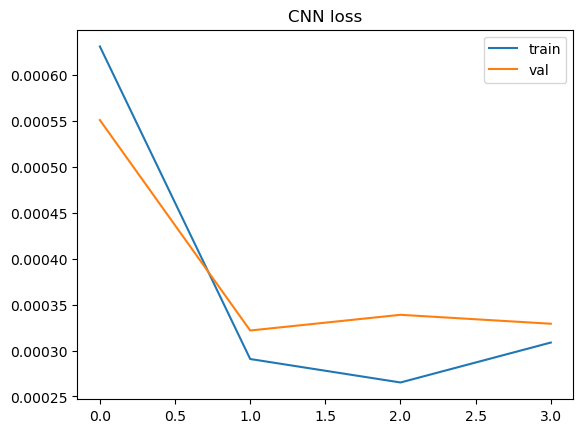

In [10]:
plt.plot(hist.history["loss"], label="train")
plt.plot(hist.history["val_loss"], label="val")
plt.title("CNN loss")
plt.legend()
plt.show()


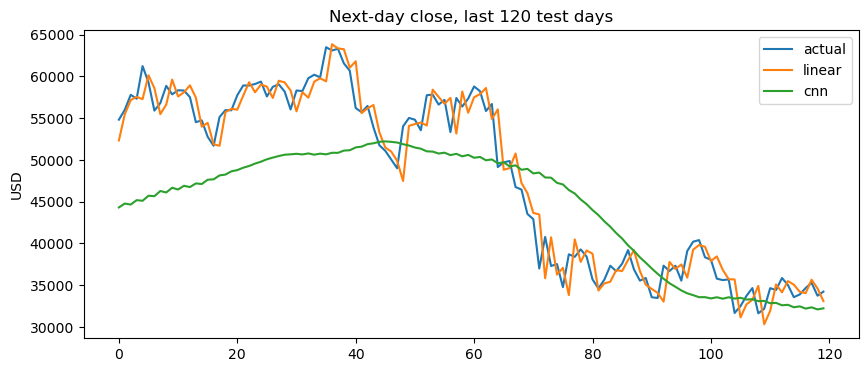

In [11]:
yt = scaler.inverse_transform(y_test.reshape(-1, 1)).ravel()
yp_lin = scaler.inverse_transform(lin_pred.reshape(-1, 1)).ravel()
yp_dl = scaler.inverse_transform(dl_pred.reshape(-1, 1)).ravel()
plt.figure(figsize=(10, 4))
plt.plot(yt[-120:], label="actual")
plt.plot(yp_lin[-120:], label="linear")
plt.plot(yp_dl[-120:], label="cnn")
plt.title("Next-day close, last 120 test days")
plt.ylabel("USD")
plt.legend()
plt.show()


In [12]:
dl.save("bitcoin_cnn.keras")


# Conclusion

I used the daily Bitcoin close from 2013 to 2021. The 30-day mean shows the trend, the return histogram shows how sharp the daily moves are, and the decomposition separates that trend from a yearly seasonal component. The split is chronological, so the test days stay in the future. The scaler uses the full series min and max, because 2021 sits far above the earlier years. Training uses only the earlier part of that split. Linear regression on the last 30 closes is the autoregressive baseline. The 1D CNN is the deep learning model: it looks at the local shape of the price window and predicts the next close. RMSE is in dollars. The CNN is saved as bitcoin_cnn.keras.
